# 1. DAILY RSI(2) MEAN REVERSION - HYPOTHESIS DEFINITION & BASELINE BACKTEST

This notebook formulates the quantitative hypothesis and establishes the baseline backtest for the **Alphaca RSI(2) Mean Reversion** strategy on **Multiple** daily bars.

### 1.1 CORE QUANTITATIVE HYPOTHESIS
The strategy exploits a structural property of equity index markets identified in our Exploratory Data Analysis:
- **Macro Trend Drift**: The Nasdaq-100 exhibits a persistent multi-decade upward drift (~10.9% CAGR since 1999).
- **Short-Term Micro Reversal**: Daily returns exhibit negative autocorrelation (Lag 1 ACF = -0.058) and a sub-diffusive Hurst exponent ($H = 0.48 < 0.50$).
- **The Core Premise**: When an asset in a macro bull market (`Close > SMA(between 190 and 250)`) experiences severe, sudden selling pressure (`RSI(2) < between 15 and 22`), institutional liquidity providers step in to absorb retail stop-losses and panics. The resulting bounce generates an asymmetric, high-probability mean-reverting edge over the subsequent 2 to 5 sessions.

### 1.2 FROZEN STRATEGY RULES
| Rule Component | Specification |
| :--- | :--- |
| **Instrument** | Multiple, Daily bars (split/dividend adjusted) |
| **Trend Filter** | `Close[t-1] > SMA(between 190 and 250)[t-1]` (evaluated at day $t-1$ close) |
| **Entry Trigger** | `RSI(2)[t-1] < between 15 and 22` (Wilder smoothing, evaluated at day $t-1$ close) |
| **Execution** | Buy at **OPEN** of day $t$ with slippage cost: `Entry = Open[t] * (1 + 0.0005)` |
| **Exit Trigger** | Two consecutive green candles: `Close[t-1] > Open[t-1]` AND `Close[t-2] > Open[t-2]` |
| **Exit Execution** | Sell at **OPEN** of day $t$ with slippage cost: `Exit = Open[t] * (1 - 0.0005)` |
| **Direction** | Long only, no price stop loss |
| **Trading Costs** | 5 bps per side (0.05% per side = 10 bps round-trip), zero commission |
| **Position Sizing** | (a) **Capital Sizing**: 100% equity per trade<br>(b) **ATR Risk Sizing**: 1% risk per trade with 2x ATR(14) stop, capped at 100% |

### 1.3 PROVENANCE & ADAPTATION
- **Academic / Practitioner Origin**: Developed by Larry Connors & Cesar Alvarez (*Short Term Trading Strategies That Work*, 2008).
- **Alphaca Refinement**: Alphaca adapted the exit logic from a fixed MA(5) cross to an agile two-consecutive-green-candles price-action exit, increasing trade velocity and reducing overnight drawdown exposure.

### 01-4 STRATEGY PARAMETERS

In [39]:
VARIANT = "v1_sp500" # only base variants 
STOP_LIMIT = 0.09

## 2. IMPORTS AND CONFIG

In [40]:
%pip install pandas_market_calendars
import os
import sys
import json
import importlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---- Paths ----
def find_upwards(name, start=None, must_be_dir=True):
    """Sube desde start (cwd por defecto) y devuelve la primera carpeta
    que contiene `name`. Devuelve esa carpeta contenedora."""
    here = (start or Path.cwd()).resolve()
    for base in (here, *here.parents):
        target = base / name
        if target.is_dir() if must_be_dir else target.exists():
            return base
    raise FileNotFoundError(f"No encontré '{name}' subiendo desde {here}")

EDGE_DIR    = find_upwards('variants')                  # carpeta del edge, cualquier nombre
utils_path  = str(find_upwards('utils') / 'utils')      # research_development/utils
engine_path = str(EDGE_DIR)
engine_dir  = str(EDGE_DIR / 'rsi2_engine')

for p in (utils_path, engine_path, engine_dir):
    if p not in sys.path:
        sys.path.insert(0, p)

from utils import compute_metrics, plot_equity_curve
from metrics import sharpe_ratio, max_drawdown
import rsi2_engine as eng
import variant_config
from variant_config import load_variant, save_json

importlib.reload(eng)   # reinicia ENGINE_DEFAULTS: nada se filtra entre variantes y recarga el motor si lo editaste

variant_config.EDGE_DIR = EDGE_DIR
assert (variant_config.EDGE_DIR / "variants").is_dir(), \
    f"Doesn't exist {variant_config.EDGE_DIR / 'variants'}"

# ---- Variant config: single source of truth ----
cfg        = load_variant(VARIANT)
eng.set_engine_defaults(**cfg.get("engine_defaults", {}))
RUN_DIR    = cfg["run_dir"]
TICKER     = cfg["instrument"]["ticker"]
DATA_START = cfg["instrument"]["start"]
OOS_START  = cfg["oos_start_ts"]
SMA_LEN    = cfg["params"]["sma_len"]
RSI_THR    = cfg["params"]["rsi_thr"]
EXIT_MODE  = cfg["params"]["exit_mode"]
SLIP_BPS   = cfg["params"]["slip_bps_per_side"]
SLIP       = SLIP_BPS / 10_000

print("Imports complete.")
print(f"Loaded rsi2_engine from: {eng.__file__}")
print(f"Edge dir: {EDGE_DIR}")
print(f"Variant: {cfg['id']} | {TICKER} | RSI(2) < {RSI_THR:g} | SMA({SMA_LEN}) | exit={EXIT_MODE} | {SLIP_BPS:g} bps/side")
print(f"Data source: {eng.ENGINE_DEFAULTS['data_source']} | swap: {eng.ENGINE_DEFAULTS['financing_bps_per_night']:g} bps/night")
print(f"Run folder: {RUN_DIR}")


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: /opt/homebrew/opt/python@3.11/bin/python3.11 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
Imports complete.
Loaded rsi2_engine from: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/RSI2/rsi2_engine.py
Edge dir: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/RSI2
Variant: RSI2.sp500.v1 | SP500 | RSI(2) < 5 | SMA(80) | exit=2green | 5 bps/side
Data source: csv_daily | swap: 2 bps/night
Run folder: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/RSI2/runs/v1_sp500


## 3. LOAD DATA AND IN-SAMPLE / OUT-OF-SAMPLE

In [41]:
# Execution rules and split date come from the variant config (previous cell).
# Daily data: yahoo or csv_intraday, depending on engine_defaults.data_source in the variant YAML.
df_raw = eng.load_data(TICKER, start=DATA_START)

print(len(df_raw), df_raw.index.dayofweek.value_counts().sort_index().to_dict())
print(df_raw.groupby(df_raw.index.year).size().to_dict())

df = eng.prepare(df_raw, sma_len=SMA_LEN)

n_is = int((df.index < OOS_START).sum())
df_is = df.iloc[:n_is].copy()
df_oos = df.iloc[n_is:].copy()
assert len(df_is) > 0 and len(df_oos) > 0, "Check split.oos_start against the history of this ticker."
oos_start = df_oos.index[0]

print("=" * 70)
print("DATA INGESTION & DATASET SPLIT")
print("=" * 70)
print(f"Total Prepared Bars: {len(df):,} ({df.index.min().strftime('%Y-%m-%d')} to {df.index.max().strftime('%Y-%m-%d')})")
print(f"In-Sample (IS, {len(df_is)/len(df)*100:.1f}%): {len(df_is):,} bars ({df_is.index.min().strftime('%Y-%m-%d')} to {df_is.index.max().strftime('%Y-%m-%d')})")
print(f"Out-of-Sample (OOS, {len(df_oos)/len(df)*100:.1f}%): {len(df_oos):,} bars ({df_oos.index.min().strftime('%Y-%m-%d')} to {df_oos.index.max().strftime('%Y-%m-%d')})")
print("=" * 70)

df.head()

5030 {0: 944, 1: 1034, 2: 1033, 3: 1012, 4: 1007}
{2006: 117, 2007: 251, 2008: 253, 2009: 252, 2010: 252, 2011: 252, 2012: 250, 2013: 252, 2014: 252, 2015: 252, 2016: 252, 2017: 251, 2018: 251, 2019: 252, 2020: 253, 2021: 252, 2022: 251, 2023: 250, 2024: 252, 2025: 250, 2026: 133}
DATA INGESTION & DATASET SPLIT
Total Prepared Bars: 4,951 (2006-11-06 to 2026-07-15)
In-Sample (IS, 60.4%): 2,990 bars (2006-11-06 to 2018-09-21)
Out-of-Sample (OOS, 39.6%): 1,961 bars (2018-09-24 to 2026-07-15)


,open,high,low,close,volume,sma,rsi2,green,ma5,atr14
time,,,,,,,,,,
2006-11-06,1364.27,1381.40,1364.27,1379.78,2.053214e+09,1315.893250,83.462315,1,1371.434,10.050397
2006-11-07,1379.75,1388.19,1379.19,1382.84,2.229103e+09,1317.747625,87.545113,1,1372.414,9.975368
2006-11-08,1382.50,1388.61,1376.29,1385.72,2.461051e+09,1319.608375,91.496701,1,1375.996,10.142842
2006-11-09,1385.43,1388.92,1377.31,1378.33,2.705669e+09,1321.089875,34.813146,0,1378.194,10.247639
2006-11-10,1378.33,1381.04,1375.60,1380.90,2.048970e+09,1322.737000,54.443264,1,1381.514,9.904236


## 4. BASELINE BACKTEST WITH FROZEN RULES

PERFORMANCE SUMMARY (NET OF 5 BPS SLIPPAGE PER SIDE)


,Period,Sizing,Trades,Win Rate,Profit Factor,Expectancy,Total Return,Sharpe,Max Drawdown
0,In-Sample (2006-2018),100% Capital,32,78.1%,2.820,0.509%,17.3%,0.40,-6.00%
1,In-Sample (2006-2018),1% ATR Risk,32,78.1%,3.161,0.307%,10.2%,0.44,-3.47%
2,Out-of-Sample (2018-2026),100% Capital,32,78.1%,1.746,0.508%,16.6%,0.39,-13.95%
3,Out-of-Sample (2018-2026),1% ATR Risk,32,78.1%,1.531,0.200%,6.3%,0.29,-7.35%
4,Full Period (2006-2026),100% Capital,64,78.1%,2.060,0.509%,36.8%,0.38,-14.61%
5,Full Period (2006-2026),1% ATR Risk,64,78.1%,1.977,0.253%,17.2%,0.36,-7.68%


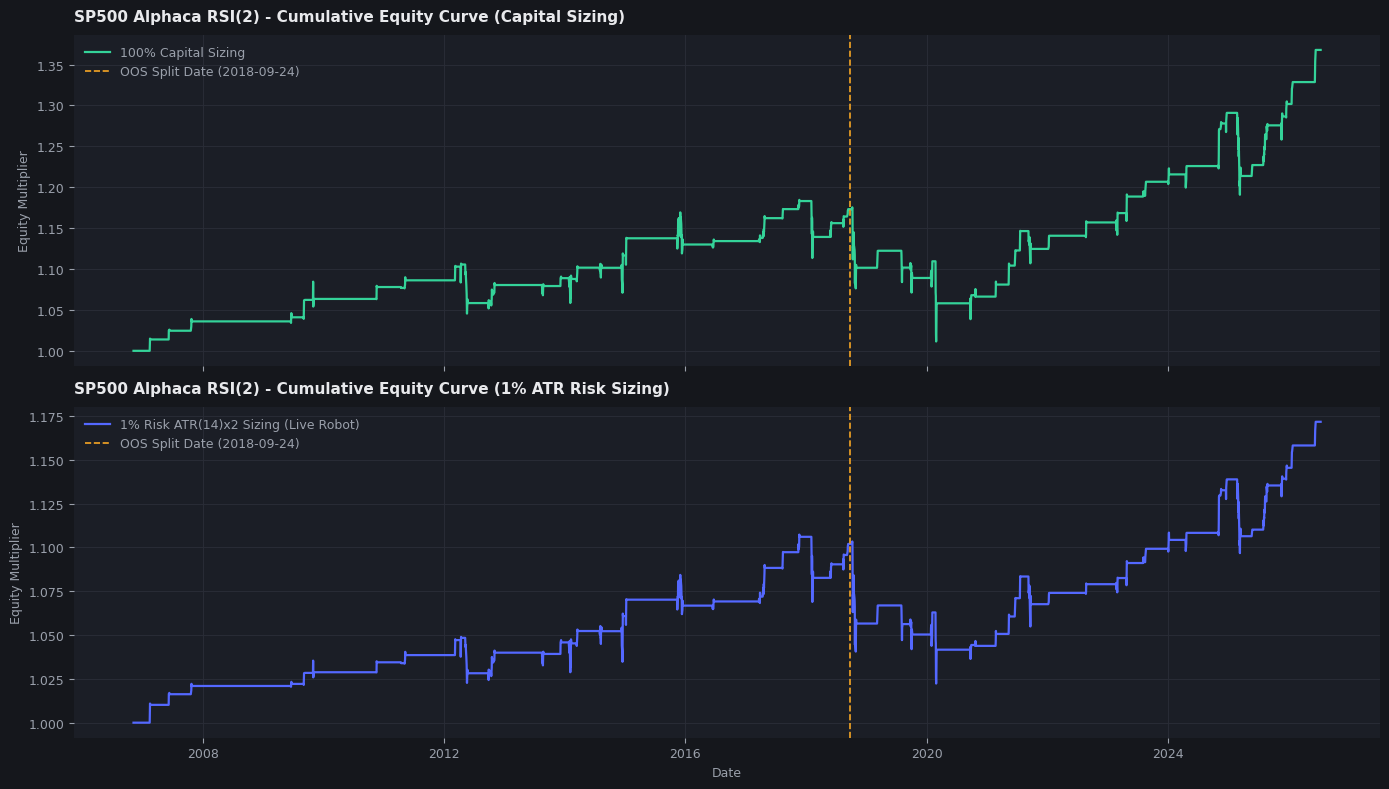

In [42]:
# Run backtest with frozen rules across IS, OOS, and Full Dataset
trades_is  = eng.run_rsi2_backtest(df_is,  rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
trades_oos = eng.run_rsi2_backtest(df_oos, rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
trades_all = eng.run_rsi2_backtest(df,     rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)

def format_perf_table(t_df, period_name, price_df):
    m_cap = compute_metrics(t_df, contract_multiplier=1.0, cost_per_trade=0.0)
    t_atr = t_df.assign(pnl=t_df['pnl_atr'], win=t_df['pnl_atr'] > 0)
    m_atr = compute_metrics(t_atr, contract_multiplier=1.0, cost_per_trade=0.0)

    ret_cap = eng.daily_returns(price_df, t_df, sizing="capital")
    ret_atr = eng.daily_returns(price_df, t_df, sizing="atr")

    eq_cap = (1.0 + ret_cap).cumprod()
    eq_atr = (1.0 + ret_atr).cumprod()

    return pd.DataFrame([
        {
            'Period': period_name,
            'Sizing': '100% Capital',
            'Trades': m_cap['num_trades'],
            'Win Rate': f"{m_cap['win_rate']:.1f}%",
            'Profit Factor': f"{m_cap['profit_factor']:.3f}",
            'Expectancy': f"{m_cap['expectancy']:.3f}%",
            'Total Return': f"{(eq_cap.iloc[-1] - 1)*100:.1f}%",
            'Sharpe': f"{sharpe_ratio(ret_cap):.2f}",
            'Max Drawdown': f"{max_drawdown(eq_cap)*100:.2f}%"
        },
        {
            'Period': period_name,
            'Sizing': '1% ATR Risk',
            'Trades': m_atr['num_trades'],
            'Win Rate': f"{m_atr['win_rate']:.1f}%",
            'Profit Factor': f"{m_atr['profit_factor']:.3f}",
            'Expectancy': f"{m_atr['expectancy']:.3f}%",
            'Total Return': f"{(eq_atr.iloc[-1] - 1)*100:.1f}%",
            'Sharpe': f"{sharpe_ratio(ret_atr):.2f}",
            'Max Drawdown': f"{max_drawdown(eq_atr)*100:.2f}%"
        }
    ])

perf_table = pd.concat([
    format_perf_table(trades_is,  f"In-Sample ({df_is.index[0].year}-{df_is.index[-1].year})", df_is),
    format_perf_table(trades_oos, f"Out-of-Sample ({df_oos.index[0].year}-{df_oos.index[-1].year})", df_oos),
    format_perf_table(trades_all, f"Full Period ({df.index[0].year}-{df.index[-1].year})", df)
], ignore_index=True)

print("=" * 80)
print(f"PERFORMANCE SUMMARY (NET OF {SLIP_BPS:g} BPS SLIPPAGE PER SIDE)")
print("=" * 80)
display(perf_table)

# Plot Equity Curves
ret_cap_all = eng.daily_returns(df, trades_all, sizing="capital")
ret_atr_all = eng.daily_returns(df, trades_all, sizing="atr")
eq_cap_all = (1.0 + ret_cap_all).cumprod()
eq_atr_all = (1.0 + ret_atr_all).cumprod()

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True, facecolor='#15171c')
for ax in (ax1, ax2):
    ax.set_facecolor('#1b1e26')
    ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(colors='#9aa0ab', labelsize=9)

split_label = f"OOS Split Date ({oos_start:%Y-%m-%d})"

ax1.plot(df.index, eq_cap_all, color='#34d399', lw=1.6, label='100% Capital Sizing')
ax1.axvline(oos_start, color='#f5a524', ls='--', lw=1.2, label=split_label)
ax1.set_title(f'{TICKER} Alphaca RSI(2) - Cumulative Equity Curve (Capital Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left', pad=10)
ax1.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax1.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

ax2.plot(df.index, eq_atr_all, color='#5468ff', lw=1.6, label='1% Risk ATR(14)x2 Sizing (Live Robot)')
ax2.axvline(oos_start, color='#f5a524', ls='--', lw=1.2, label=split_label)
ax2.set_title(f'{TICKER} Alphaca RSI(2) - Cumulative Equity Curve (1% ATR Risk Sizing)', color='#e8e9ec', fontweight='bold', fontsize=11, loc='left', pad=10)
ax2.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax2.set_xlabel('Date', color='#9aa0ab', fontsize=9)
ax2.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

## 4.5 ANNUAL RETURNS

ANNUAL RETURNS | 2006-11-06 -> 2026-07-15 | partial years excluded from means


,ATR (live robot),100% Capital
CAGR (whole period),+0.81%,+1.60%
Mean annual (full years),+0.73%,+1.44%
Median annual (full years),+0.56%,+1.20%
Best year,2024 +3.61%,2024 +6.98%
Worst year,2018 -4.48%,2018 -6.89%
Positive years,15 / 19 (79%),14 / 19 (74%)
Years breaching the limit,0,-


,ATR return,ATR MaxDD,Capital return,Days,Note,Breaches limit
Year,,,,,,
2006,+0.00%,0.00%,+0.00%,38,partial year,
2007,+2.10%,-0.12%,+3.60%,251,,
2008,+0.00%,0.00%,+0.00%,253,,
2009,+0.77%,-0.92%,+2.65%,252,,
2010,+0.55%,-0.06%,+1.37%,252,,
2011,+0.40%,-0.18%,+0.76%,252,,
2012,+0.13%,-2.50%,-0.53%,250,,
2013,+0.56%,-0.70%,+0.78%,252,,
2014,+1.44%,-1.94%,+2.55%,252,,


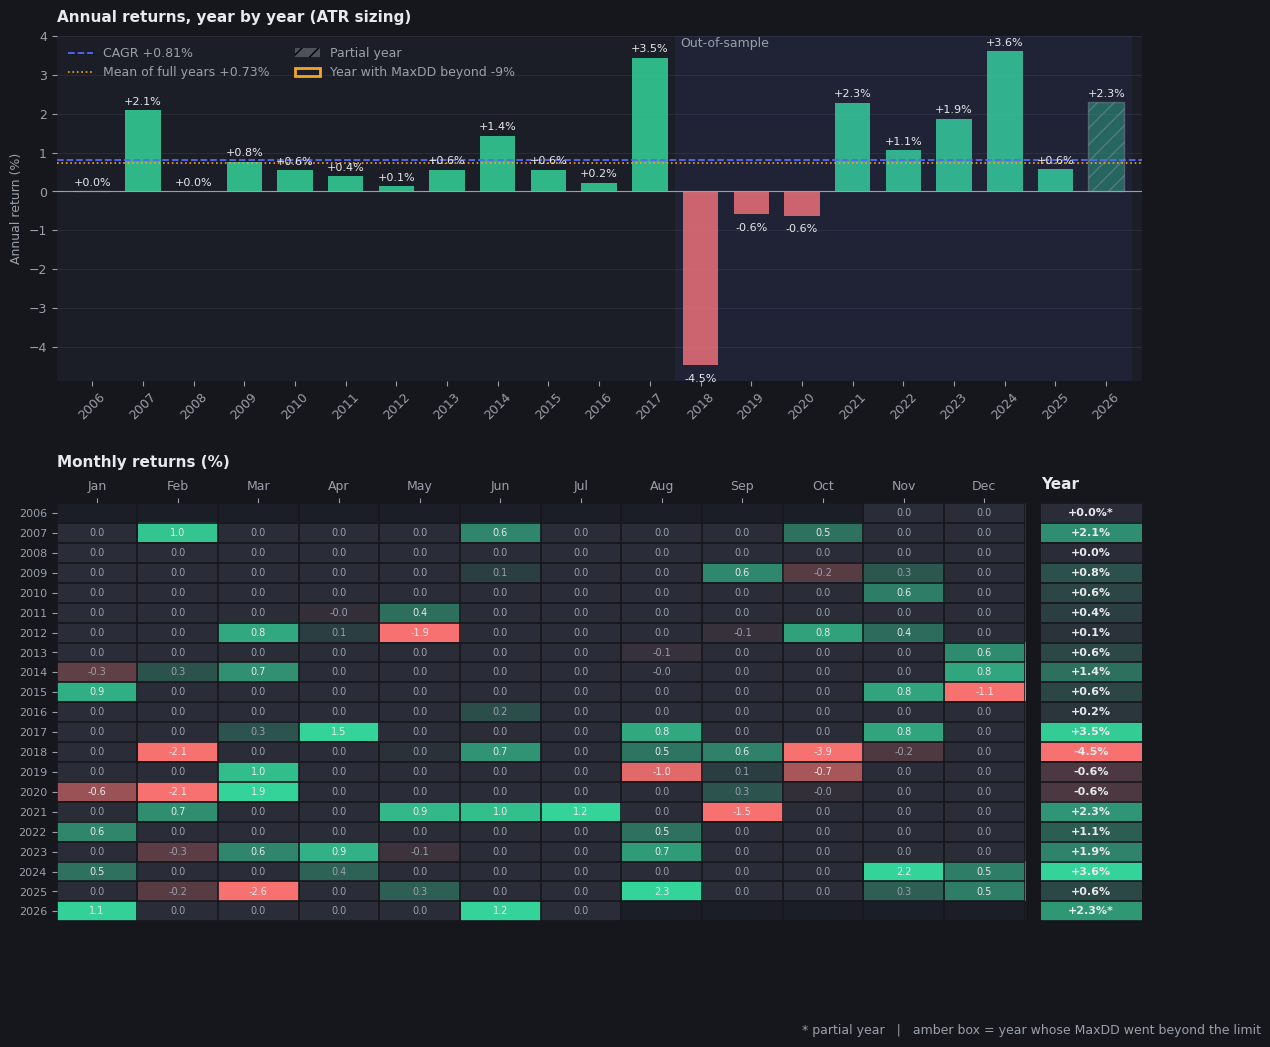

In [43]:
# ===== 4.6  ANNUAL RETURNS: average and year by year since the start of the data =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Rectangle
from matplotlib.lines import Line2D

LIMIT = STOP_LIMIT                                   # same hard limit as 4.5 (used to flag years that breach it)
BG, PANEL, GRID, TXT, TXT2 = '#15171c', '#1b1e26', '#2a2d37', '#e8e9ec', '#9aa0ab'
GREEN, RED, AMBER, BLUE = '#34d399', '#f87171', '#f5a524', '#5468ff'
MONTHS = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']

ret_atr = eng.daily_returns(df, trades_all, sizing="atr").astype(float)
ret_cap = eng.daily_returns(df, trades_all, sizing="capital").astype(float)

def by_year(ret):
    g = ret.groupby(ret.index.year)
    return pd.DataFrame({
        "Return": g.apply(lambda x: (1 + x).prod() - 1),
        "MaxDD":  g.apply(lambda x: ((1 + x).cumprod() / (1 + x).cumprod().cummax() - 1).min()),
        "Days":   g.size(),
    })

def cagr(ret):
    yrs = (ret.index[-1] - ret.index[0]).days / 365.25
    return (1 + ret).prod() ** (1 / yrs) - 1

a, c = by_year(ret_atr), by_year(ret_cap)
first_y, last_y = ret_atr.index[0].year, ret_atr.index[-1].year
a["Partial"] = [(y in (first_y, last_y)) and d < 0.9 * 252 for y, d in zip(a.index, a["Days"])]

tbl = pd.DataFrame({
    "ATR return":     a["Return"],
    "ATR MaxDD":      a["MaxDD"],
    "Capital return": c["Return"],
    "Days":           a["Days"],
    "Note":           np.where(a["Partial"], "partial year", ""),
    "Breaches limit": np.where(a["MaxDD"] <= -LIMIT, "YES", ""),
})
tbl.index.name = "Year"

full = a[~a["Partial"]]
summary = pd.DataFrame({
    "ATR (live robot)": {
        "CAGR (whole period)":        cagr(ret_atr),
        "Mean annual (full years)":   full["Return"].mean(),
        "Median annual (full years)": full["Return"].median(),
        "Best year":                  f"{full['Return'].idxmax()}  {full['Return'].max():+.2%}",
        "Worst year":                 f"{full['Return'].idxmin()}  {full['Return'].min():+.2%}",
        "Positive years":             f"{(full['Return'] > 0).sum()} / {len(full)}  ({(full['Return'] > 0).mean():.0%})",
        "Years breaching the limit":  int((a['MaxDD'] <= -LIMIT).sum()),
    },
    "100% Capital": {
        "CAGR (whole period)":        cagr(ret_cap),
        "Mean annual (full years)":   c.loc[full.index, "Return"].mean(),
        "Median annual (full years)": c.loc[full.index, "Return"].median(),
        "Best year":                  f"{c.loc[full.index, 'Return'].idxmax()}  {c.loc[full.index, 'Return'].max():+.2%}",
        "Worst year":                 f"{c.loc[full.index, 'Return'].idxmin()}  {c.loc[full.index, 'Return'].min():+.2%}",
        "Positive years":             f"{(c.loc[full.index, 'Return'] > 0).sum()} / {len(full)}  ({(c.loc[full.index, 'Return'] > 0).mean():.0%})",
        "Years breaching the limit":  "-",
    },
})

print("=" * 78)
print(f"ANNUAL RETURNS | {ret_atr.index[0]:%Y-%m-%d} -> {ret_atr.index[-1]:%Y-%m-%d} | partial years excluded from means")
print("=" * 78)
display(summary.style.format(lambda v: f"{v:+.2%}" if isinstance(v, (float, np.floating)) else v))

def _color(v):
    return f"color: {GREEN}" if v > 0 else f"color: {RED}"
sty = tbl.style.format({"ATR return": "{:+.2%}", "ATR MaxDD": "{:.2%}", "Capital return": "{:+.2%}"})
sty = (sty.map if hasattr(sty, "map") else sty.applymap)(_color, subset=["ATR return", "Capital return"])
display(sty)

# ------------------------------------------------------------------ charts
def style(ax, title, ylabel=None):
    ax.set_facecolor(PANEL)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(colors=TXT2, labelsize=9)
    ax.set_title(title, color=TXT, fontweight='bold', fontsize=11, loc='left', pad=10)
    if ylabel: ax.set_ylabel(ylabel, color=TXT2, fontsize=9)

# monthly matrix (years x 12) for the heatmap
monthly = ((1 + ret_atr).groupby([ret_atr.index.year, ret_atr.index.month]).prod() - 1).unstack()
monthly = monthly.reindex(columns=range(1, 13)) * 100
n_years = len(monthly)

fig = plt.figure(figsize=(14, 5.2 + 0.30 * n_years), facecolor=BG)
gs = GridSpec(2, 2, height_ratios=[5.2, 0.30 * n_years], width_ratios=[12, 1.25],
              hspace=0.32, wspace=0.03, figure=fig)

# 1) annual bars -------------------------------------------------------------
ax = fig.add_subplot(gs[0, :])
style(ax, 'Annual returns, year by year (ATR sizing)', 'Annual return (%)')
ax.grid(True, axis='y', color=GRID, linewidth=0.8, alpha=0.9); ax.set_axisbelow(True)

yrs = a.index.values
vals = a["Return"].values * 100
bars = ax.bar(yrs, vals, color=[GREEN if v > 0 else RED for v in vals], alpha=0.85, width=0.7)
for b, (_, row) in zip(bars, a.iterrows()):
    if row["Partial"]:
        b.set_alpha(0.4); b.set_hatch('//'); b.set_edgecolor(TXT2)
    if row["MaxDD"] <= -LIMIT:
        b.set_edgecolor(AMBER); b.set_linewidth(2.0)
    v = row["Return"] * 100
    ax.annotate(f"{v:+.1f}%", (b.get_x() + b.get_width() / 2, v), xytext=(0, 4 if v >= 0 else -12),
                textcoords='offset points', ha='center', color=TXT, fontsize=8)

ax.axhline(0, color=TXT2, lw=0.8)
ax.axhline(cagr(ret_atr) * 100, color=BLUE, ls='--', lw=1.3)
ax.axhline(full["Return"].mean() * 100, color=AMBER, ls=':', lw=1.2)
ax.set_xticks(yrs); ax.set_xticklabels(yrs, rotation=45, color=TXT2, fontsize=9)
ax.set_xlim(yrs.min() - 0.7, yrs.max() + 0.7)
try:                                                  # shade the out-of-sample years
    ax.axvspan(oos_start.year - 0.5, last_y + 0.5, color=BLUE, alpha=0.07, lw=0)
    ax.text(oos_start.year - 0.4, ax.get_ylim()[1] * 0.93, "Out-of-sample", color=TXT2, fontsize=9)
except NameError:
    pass
ax.legend(handles=[
    Line2D([0], [0], color=BLUE, ls='--', lw=1.3, label=f"CAGR {cagr(ret_atr):+.2%}"),
    Line2D([0], [0], color=AMBER, ls=':', lw=1.2, label=f"Mean of full years {full['Return'].mean():+.2%}"),
    Patch(facecolor=TXT2, alpha=0.4, hatch='//', label='Partial year'),
    Patch(facecolor='none', edgecolor=AMBER, lw=2, label=f"Year with MaxDD beyond -{LIMIT:.0%}"),
], frameon=False, labelcolor=TXT2, fontsize=9, loc='upper left', ncol=2)

# 2) monthly heatmap -----------------------------------------------------------
cmap = LinearSegmentedColormap.from_list('rg', [RED, '#2a2d37', GREEN]); cmap.set_bad(PANEL)
vmax = max(float(np.nanpercentile(np.abs(monthly.values), 95)), 0.5)

axh = fig.add_subplot(gs[1, 0])
style(axh, 'Monthly returns (%)')
axh.imshow(np.ma.masked_invalid(monthly.values), cmap=cmap, vmin=-vmax, vmax=vmax, aspect='auto')
axh.set_xticks(range(12)); axh.set_xticklabels(MONTHS, color=TXT2, fontsize=9)
axh.set_yticks(range(n_years)); axh.set_yticklabels(monthly.index, color=TXT2, fontsize=8)
axh.xaxis.tick_top()
axh.set_xticks(np.arange(-0.5, 12, 1), minor=True); axh.set_yticks(np.arange(-0.5, n_years, 1), minor=True)
axh.grid(which='minor', color=BG, linewidth=1.2); axh.tick_params(which='minor', length=0)
for i in range(n_years):
    for j in range(12):
        v = monthly.values[i, j]
        if not np.isnan(v):
            axh.text(j, i, f"{v:.1f}", ha='center', va='center', fontsize=7,
                     color=TXT if abs(v) > vmax * 0.35 else TXT2)

# 3) year total column -----------------------------------------------------------
axy = fig.add_subplot(gs[1, 1])
style(axy, 'Year')
yv = (a["Return"].values * 100).reshape(-1, 1)
vmax_y = max(float(np.nanpercentile(np.abs(yv), 95)), 1.0)
axy.imshow(yv, cmap=cmap, vmin=-vmax_y, vmax=vmax_y, aspect='auto')
axy.set_xticks([]); axy.set_yticks([])
axy.set_yticks(np.arange(-0.5, n_years, 1), minor=True)
axy.grid(which='minor', axis='y', color=BG, linewidth=1.2); axy.tick_params(which='minor', length=0)
for i, (_, row) in enumerate(a.iterrows()):
    axy.text(0, i, f"{row['Return'] * 100:+.1f}%{'*' if row['Partial'] else ''}", ha='center', va='center',
             fontsize=8, fontweight='bold', color=TXT)
    if row["MaxDD"] <= -LIMIT:
        axy.add_patch(Rectangle((-0.5, i - 0.5), 1, 1, fill=False, ec=AMBER, lw=1.8))
fig.text(0.985, 0.012, "* partial year   |   amber box = year whose MaxDD went beyond the limit",
         color=TXT2, fontsize=9, ha='right')

plt.show()

## 5. SANITY CHECKS & VERIFICATION

In [44]:
print("=" * 70)
print("SANITY CHECKS & REPRODUCIBILITY")
print("=" * 70)

# 1. Assert No Lookahead Bias and index alignment
# entry_time must be strictly after the signal bar, and i_ent / i_sal must point
# to the correct rows of df.
for idx, row in trades_all.iterrows():
    signal_time = df.index[row['i_ent'] - 1]
    entry_time = row['entry_time']
    assert entry_time > signal_time, f"Lookahead detected at trade {idx}!"
    assert df.index[int(row['i_ent'])] == entry_time, f"i_ent misaligned at trade {idx}!"
    assert df.index[int(row['i_sal'])] == row['exit_time'], f"i_sal misaligned at trade {idx}!"
    expected_open = df.loc[entry_time, 'open'] * (1.0 + SLIP)
    assert np.isclose(row['entry_price'], expected_open, atol=1e-4), f"Entry price mismatch at trade {idx}!"

print(f"Sanity Check 1: PASSED. Strictly zero lookahead bias verified across all {len(trades_all)} trades.")
print("   - Signal evaluated at close of day t-1.")
print(f"   - Execution at open of day t with +{SLIP_BPS:.0f} bps slippage applied.")
print("   - i_ent / i_sal aligned with the price DataFrame.")

# 2. Trade Distribution per Calendar Year
trades_all['year'] = pd.to_datetime(trades_all['entry_time']).dt.year
trades_per_year = trades_all.groupby('year').size()

print("\nSanity Check 2: Trade Frequency per Year:")
print(f"   - Average trades per year: {trades_per_year.mean():.1f}")
print(f"   - Min trades: {trades_per_year.min()} ({trades_per_year.idxmin()}) | Max trades: {trades_per_year.max()} ({trades_per_year.idxmax()})")

# 3. Cross-Check with Alphaca Reference Benchmark (only applies to 15/200/2green reference rules)
is_reference = (TICKER, RSI_THR, SMA_LEN, EXIT_MODE) == ("QQQ", 15.0, 200, "2green")
tis_ref_path = "/Users/luyandy/Downloads/TIS-RSI2-Research-main/resultados/metricas.json"

if not is_reference:
    print("\nSanity Check 3: skipped (not reference rules 15/200/2green).")
elif os.path.exists(tis_ref_path):
    with open(tis_ref_path) as f:
        tis_data = json.load(f)
    tis_is = tis_data['fase1']['IS']
    tis_oos = tis_data['fase1']['OOS']

    comp_df = pd.DataFrame([
        {
            'Metric': 'In-Sample Trades (N)',
            'Engine (Ours)': len(trades_is),
            'TIS Benchmark': tis_is['n'],
            'Match': len(trades_is) == tis_is['n']
        },
        {
            'Metric': 'In-Sample Profit Factor',
            'Engine (Ours)': f"{compute_metrics(trades_is, 1.0)['profit_factor']:.3f}",
            'TIS Benchmark': f"{tis_is['pf']:.3f}",
            'Match': np.isclose(compute_metrics(trades_is, 1.0)['profit_factor'], tis_is['pf'], atol=1e-3)
        },
        {
            'Metric': 'Out-of-Sample Trades (N)',
            'Engine (Ours)': len(trades_oos),
            'TIS Benchmark': tis_oos['n'],
            'Match': len(trades_oos) == tis_oos['n']
        },
        {
            'Metric': 'Out-of-Sample Profit Factor',
            'Engine (Ours)': f"{compute_metrics(trades_oos, 1.0)['profit_factor']:.3f}",
            'TIS Benchmark': f"{tis_oos['pf']:.3f}",
            'Match': np.isclose(compute_metrics(trades_oos, 1.0)['profit_factor'], tis_oos['pf'], atol=1e-3)
        }
    ])
    print("\nSanity Check 3: Comparison with Alphaca Reference Benchmark:")
    display(comp_df)
else:
    print("\nSanity Check 3: Alphaca benchmark file not found at expected location.")

SANITY CHECKS & REPRODUCIBILITY
Sanity Check 1: PASSED. Strictly zero lookahead bias verified across all 64 trades.
   - Signal evaluated at close of day t-1.
   - Execution at open of day t with +5 bps slippage applied.
   - i_ent / i_sal aligned with the price DataFrame.

Sanity Check 2: Trade Frequency per Year:
   - Average trades per year: 3.4
   - Min trades: 1 (2010) | Max trades: 6 (2012)

Sanity Check 3: skipped (not reference rules 15/200/2green).


## 6. REFERENCE VARIANT: CONNORS BOOK RULES VS. ALPHACA RULES

VARIANT COMPARISON: Alphaca RULES VS. CONNORS BOOK RULES


,Strategy Variant,Trades,Win Rate,Profit Factor,Expectancy,Avg Holding (Bars),Sharpe,Max Drawdown
0,"Alphaca Version (RSI<5, SMA=80, 2 Green Candle...",64,78.1%,2.060,0.509%,4.7,0.38,-14.61%
1,"Connors Book Version (RSI<5, Close>MA5 Exit)",85,77.6%,1.915,0.387%,3.2,0.35,-14.41%


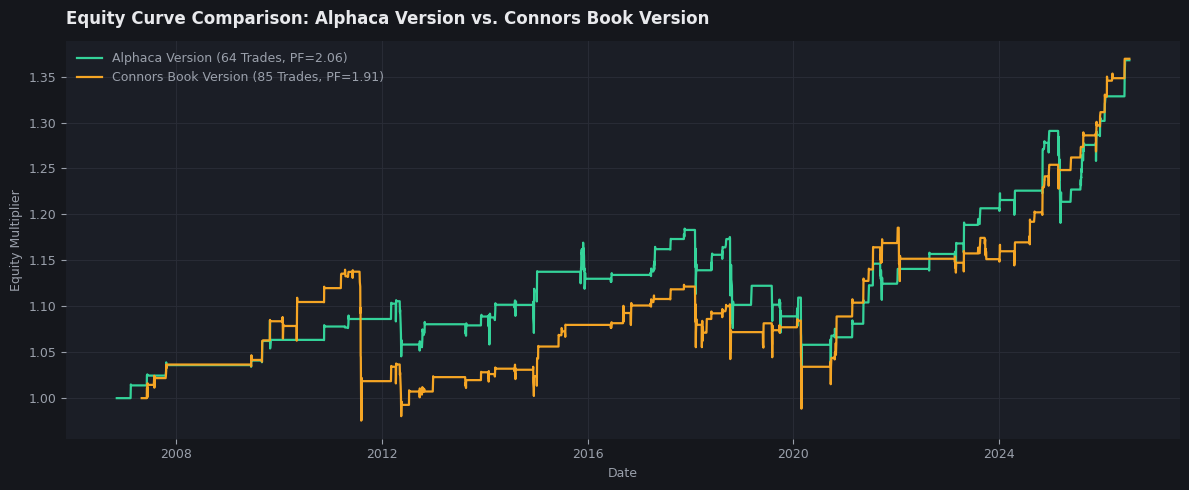

In [45]:
# Connors Original Book Rules: RSI(2) <= 5, Exit on Close > MA(5), Close > SMA(200)
df_connors = eng.prepare(df_raw, sma_len=200)
df_connors = df_connors[df_connors.index >= df.index[0]]
trades_connors = eng.run_rsi2_backtest(df_connors, rsi_thr=5.0, sma_len=200, exit_mode="ma5", slip_bps_per_side=SLIP_BPS)

m_tis = compute_metrics(trades_all, 1.0, 0.0)
m_con = compute_metrics(trades_connors, 1.0, 0.0)

ret_tis = eng.daily_returns(df, trades_all, "capital")
ret_con = eng.daily_returns(df_connors, trades_connors, "capital")
eq_tis = (1 + ret_tis).cumprod()
eq_con = (1 + ret_con).cumprod()

comp_variants = pd.DataFrame([
    {
        'Strategy Variant': f"Alphaca Version (RSI<{RSI_THR:g}, SMA={SMA_LEN}, 2 Green Candles Exit)",
        'Trades': m_tis['num_trades'],
        'Win Rate': f"{m_tis['win_rate']:.1f}%",
        'Profit Factor': f"{m_tis['profit_factor']:.3f}",
        'Expectancy': f"{m_tis['expectancy']:.3f}%",
        'Avg Holding (Bars)': f"{trades_all['bars'].mean():.1f}",
        'Sharpe': f"{sharpe_ratio(ret_tis):.2f}",
        'Max Drawdown': f"{max_drawdown(eq_tis)*100:.2f}%"
    },
    {
        'Strategy Variant': 'Connors Book Version (RSI<5, Close>MA5 Exit)',
        'Trades': m_con['num_trades'],
        'Win Rate': f"{m_con['win_rate']:.1f}%",
        'Profit Factor': f"{m_con['profit_factor']:.3f}",
        'Expectancy': f"{m_con['expectancy']:.3f}%",
        'Avg Holding (Bars)': f"{trades_connors['bars'].mean():.1f}",
        'Sharpe': f"{sharpe_ratio(ret_con):.2f}",
        'Max Drawdown': f"{max_drawdown(eq_con)*100:.2f}%"
    }
])

print("=" * 80)
print("VARIANT COMPARISON: Alphaca RULES VS. CONNORS BOOK RULES")
print("=" * 80)
display(comp_variants)

# Visual Comparison of Variants
fig, ax = plt.subplots(figsize=(12, 5), facecolor='#15171c')
ax.set_facecolor('#1b1e26')
ax.grid(True, color='#2a2d37', linewidth=0.8, alpha=0.9)
for s in ax.spines.values():
    s.set_visible(False)
ax.tick_params(colors='#9aa0ab', labelsize=9)

ax.plot(df.index, eq_tis, color='#34d399', lw=1.6,
        label=f"Alphaca Version ({m_tis['num_trades']} Trades, PF={m_tis['profit_factor']:.2f})")
ax.plot(df_connors.index, eq_con, color='#f5a524', lw=1.6,
        label=f"Connors Book Version ({m_con['num_trades']} Trades, PF={m_con['profit_factor']:.2f})")
ax.set_title('Equity Curve Comparison: Alphaca Version vs. Connors Book Version', color='#e8e9ec', fontweight='bold', fontsize=12, loc='left', pad=12)
ax.set_ylabel('Equity Multiplier', color='#9aa0ab', fontsize=9)
ax.set_xlabel('Date', color='#9aa0ab', fontsize=9)
ax.legend(frameon=False, labelcolor='#9aa0ab', fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

## 6.5 COMPARISON

In [46]:
BASE_RSI, BASE_SMA = 15.0, 200

df_base_full = eng.prepare(df_raw, sma_len=BASE_SMA)
start = max(df.index[0], df_base_full.index[0])
d_cfg = df[df.index >= start]
d_base = df_base_full[df_base_full.index >= start]
assert d_cfg.index.equals(d_base.index), "Date index mismatch between comparison series."

t_cfg = eng.run_rsi2_backtest(d_cfg, rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
t_base = eng.run_rsi2_backtest(d_base, rsi_thr=BASE_RSI, sma_len=BASE_SMA, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)

r_cfg = eng.daily_returns(d_cfg, t_cfg, sizing="atr")
r_base = eng.daily_returns(d_base, t_base, sizing="atr")
eq_cfg, eq_base = (1 + r_cfg).cumprod(), (1 + r_base).cumprod()

def _row(name, t, r, eq):
    m = compute_metrics(t, 1.0, 0.0)
    return {'Variant': name, 'Trades': m['num_trades'], 'Win Rate': f"{m['win_rate']:.1f}%",
            'Profit Factor': f"{m['profit_factor']:.3f}", 'Sharpe': f"{sharpe_ratio(r):.2f}",
            'Max Drawdown': f"{max_drawdown(eq)*100:.2f}%"}

print("=" * 80)
print(f"CONFIGURED ({RSI_THR:g}/{SMA_LEN}) vs BASELINE ({BASE_RSI:g}/{BASE_SMA})  |  common window: "
      f"{d_cfg.index[0]:%Y-%m-%d} to {d_cfg.index[-1]:%Y-%m-%d}  |  sizing ATR")
print("=" * 80)
display(pd.DataFrame([_row(f"Configured ({RSI_THR:g}/{SMA_LEN})", t_cfg, r_cfg, eq_cfg),
                      _row(f"Baseline ({BASE_RSI:g}/{BASE_SMA})", t_base, r_base, eq_base)]))

in_cfg, in_base = (r_cfg != 0), (r_base != 0)
print(f"Daily returns correlation             : {r_cfg.corr(r_base):.3f}")
print(f"Configured entries matching baseline  : {t_cfg['entry_time'].isin(t_base['entry_time']).mean():.0%}")
print(f"Baseline entries matching configured  : {t_base['entry_time'].isin(t_cfg['entry_time']).mean():.0%}")
print(f"Configured exits matching baseline    : {t_cfg['exit_time'].isin(t_base['exit_time']).mean():.0%}")
print(f"Days in position shared between both  : "
      f"{(in_cfg & in_base).sum() / max(in_cfg.sum(), 1):.0%}")

CONFIGURED (5/80) vs BASELINE (15/200)  |  common window: 2007-05-02 to 2026-07-15  |  sizing ATR


,Variant,Trades,Win Rate,Profit Factor,Sharpe,Max Drawdown
0,Configured (5/80),63,77.8%,2.014,0.34,-7.68%
1,Baseline (15/200),199,67.8%,1.459,0.30,-9.22%


Daily returns correlation             : 0.628
Configured entries matching baseline  : 22%
Baseline entries matching configured  : 7%
Configured exits matching baseline    : 97%
Days in position shared between both  : 99%


HARD RISK LIMIT CHECK | limit -9% | stage 252 days | ATR sizing, r0 = 1.00% | FULL period


,Hist MDD,Worst stage loss,Stages > limit,P(touch limit),MDD p95 (stage),OK
r,,,,,,
0.20%,-1.55%,-1.21%,0.00%,0.00%,-0.94%,True
0.30%,-2.32%,-1.82%,0.00%,0.00%,-1.41%,True
0.40%,-3.09%,-2.42%,0.00%,0.00%,-1.87%,True
0.50%,-3.86%,-3.02%,0.00%,0.00%,-2.34%,True
0.60%,-4.63%,-3.63%,0.00%,0.00%,-2.80%,True
0.70%,-5.39%,-4.23%,0.00%,0.00%,-3.27%,True
0.80%,-6.16%,-4.83%,0.00%,0.00%,-3.73%,True
0.90%,-6.92%,-5.43%,0.00%,0.03%,-4.19%,True
1.00%,-7.68%,-6.03%,0.00%,0.05%,-4.65%,True


Worst historical drawdown at r=1.00%: -7.68% (2017-11-21 -> 2020-02-28)
Verdict at r=1.00%: PASS  (stage loss -6.03% vs -9%, P(touch) 0.1% vs 5%; trailing MDD for reference -7.68%)
Largest r in the grid that passes: 1.00%
Note: history and bootstrap can't prove 'never'; they bound how likely it is. No hard stop is simulated.

Drawdown by period (ATR sizing, r = 1.00%) - a drawdown that straddles the IS/OOS cut looks smaller in each part:


,Max drawdown,Worst stage loss,vs -9%
Period,,,
In-Sample,-3.47%,-2.60%,PASS
Out-of-Sample,-7.35%,-5.70%,PASS
Full,-7.68%,-6.03%,PASS


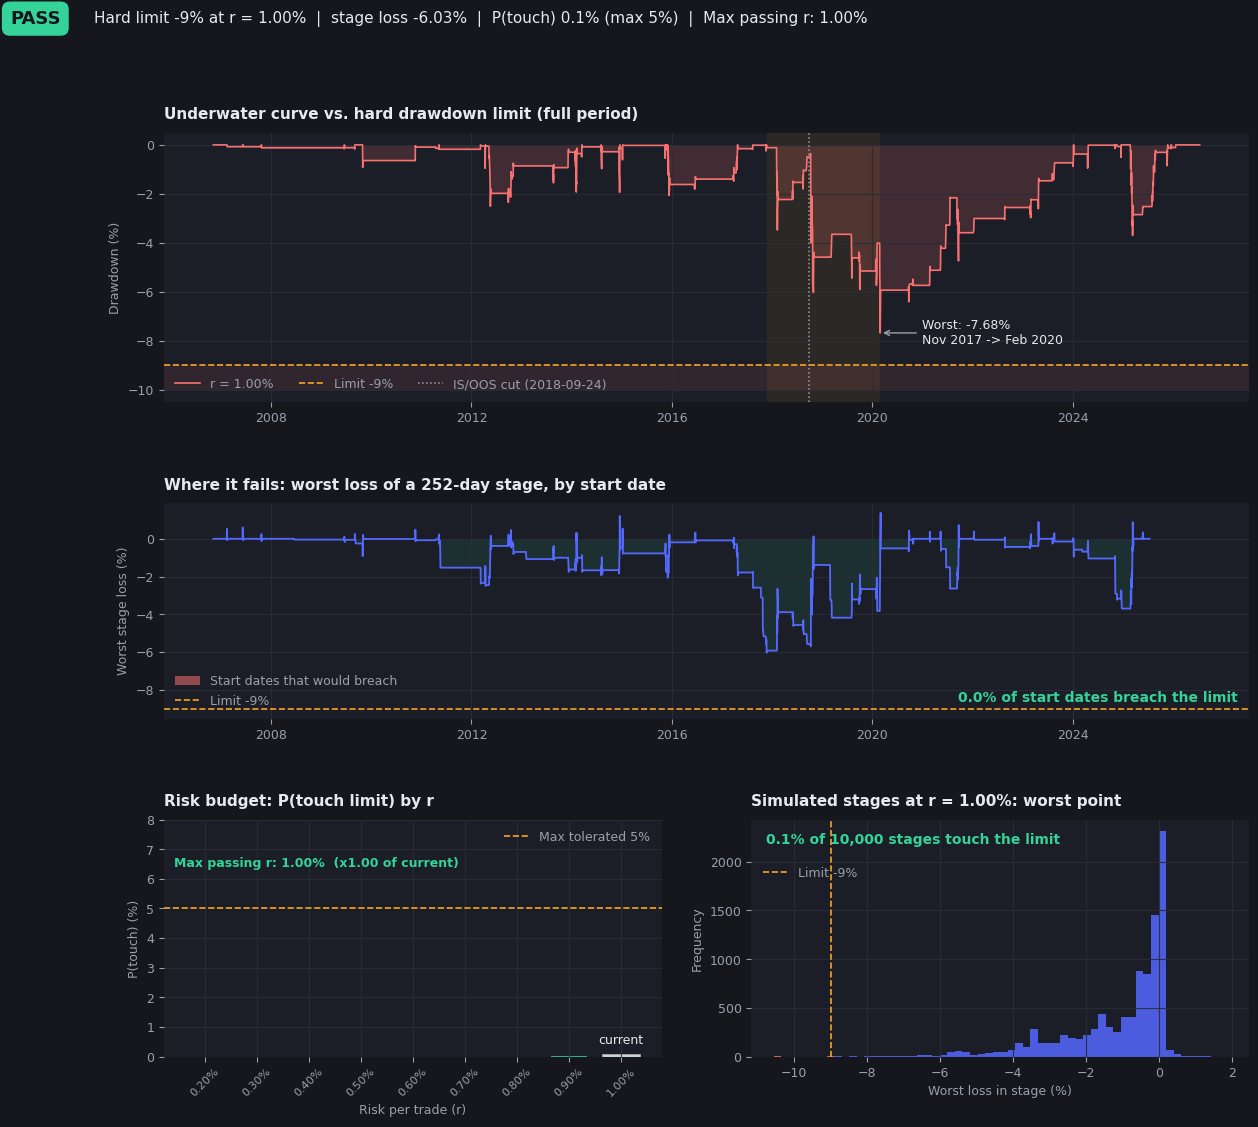

In [47]:
# ===== 4.5  HARD RISK LIMIT CHECK: drawdown must never touch the platform limit =====
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from numpy.lib.stride_tricks import sliding_window_view

LIMIT      = STOP_LIMIT      # Axi Select hard limit (Pro M: 0.10)
R0         = 0.01      # r used by the ATR sizing in this run
STAGE_DAYS = 252       # trading days a stage lasts (start-anchored test)
P_MAX      = 0.05      # max tolerated probability of touching the limit within a stage
N_SIM, BLOCK, SEED = 10_000, 20, 42
R_GRID     = [0.002, 0.003, 0.004, 0.005, 0.006, 0.007, 0.008, 0.009, 0.010]

# Which loss decides PASS/FAIL (keep it equal to the GATE of the 3D cell):
#   "stage"    = worst loss vs the balance at the start of any stage (limit NOT trailing)
#   "trailing" = max drawdown from the running peak (stricter)
GATE     = "stage"
GATE_COL = "Worst stage loss" if GATE == "stage" else "Hist MDD"

# palette (same as the rest of the notebook)
BG, PANEL, GRID, TXT, TXT2 = '#15171c', '#1b1e26', '#2a2d37', '#e8e9ec', '#9aa0ab'
GREEN, RED, AMBER, BLUE = '#34d399', '#f87171', '#f5a524', '#5468ff'

# The limit applies to the account over ANY stretch of time, so the gate uses the FULL period.
ret0 = eng.daily_returns(df, trades_all, sizing="atr").astype(float)

def underwater(ret):
    eq = (1 + ret).cumprod()
    return eq, eq / eq.cummax() - 1

def stage_losses(ret, window):
    """Worst loss vs. the balance on day s, for every possible stage start s (Axi: not trailing)."""
    w = sliding_window_view(ret.values, window)
    return np.cumprod(1 + w, axis=1).min(axis=1) - 1

# one bootstrap of daily returns (circular blocks), reused for every r by linear scaling
rng = np.random.default_rng(SEED)
v = ret0.values
n_blocks = int(np.ceil(STAGE_DAYS / BLOCK))
idx = (rng.integers(0, len(v), size=(N_SIM, n_blocks))[:, :, None] + np.arange(BLOCK)) % len(v)
sim0 = v[idx.reshape(N_SIM, -1)[:, :STAGE_DAYS]]

rows, min_paths = [], {}
for r in sorted(set(R_GRID + [R0])):
    k = r / R0
    ret = ret0 * k
    _, dd = underwater(ret)
    sl = stage_losses(ret, STAGE_DAYS)
    cum = np.cumprod(1 + sim0 * k, axis=1)
    min_paths[r] = cum.min(axis=1) - 1                      # worst point of each simulated stage
    mdd_sim = (cum / np.maximum.accumulate(cum, axis=1) - 1).min(axis=1)
    rows.append({"r": r, "Hist MDD": dd.min(), "Worst stage loss": sl.min(),
                 "Stages > limit": (sl <= -LIMIT).mean(),
                 "P(touch limit)": (min_paths[r] <= -LIMIT).mean(),
                 "MDD p95 (stage)": np.percentile(mdd_sim, 5)})
res = pd.DataFrame(rows).set_index("r")
res["OK"] = (res[GATE_COL] >= -LIMIT) & (res["P(touch limit)"] <= P_MAX)

ok_r = res.index[res["OK"]]
r_max = ok_r.max() if len(ok_r) else None
cur = res.loc[R0]
RISK_OK = bool(cur["OK"])

print("=" * 78)
print(f"HARD RISK LIMIT CHECK | limit -{LIMIT:.0%} | stage {STAGE_DAYS} days | ATR sizing, r0 = {R0:.2%} | FULL period")
print("=" * 78)
fmt = {c: "{:.2%}" for c in res.columns if c != "OK"}
display(res.rename(index=lambda x: f"{x:.2%}").style.format(fmt))

eq0, dd0 = underwater(ret0)
trough = dd0.idxmin(); peak = eq0.loc[:trough].idxmax()
print(f"Worst historical drawdown at r={R0:.2%}: {dd0.min():.2%} ({peak:%Y-%m-%d} -> {trough:%Y-%m-%d})")
print(f"Verdict at r={R0:.2%}: {'PASS' if RISK_OK else 'FAIL'}  "
      f"({GATE} loss {cur[GATE_COL]:.2%} vs -{LIMIT:.0%}, P(touch) {cur['P(touch limit)']:.1%} vs {P_MAX:.0%}; "
      f"trailing MDD for reference {cur['Hist MDD']:.2%})")
print(f"Largest r in the grid that passes: {'none' if r_max is None else f'{r_max:.2%}'}")
print("Note: history and bootstrap can't prove 'never'; they bound how likely it is. No hard stop is simulated.")

# ---- same drawdown, split by period: explains why IS alone can look fine while the full run fails ----
try:
    parts = []
    for name, d, t in (("In-Sample", df_is, trades_is), ("Out-of-Sample", df_oos, trades_oos), ("Full", df, trades_all)):
        rr = eng.daily_returns(d, t, sizing="atr").astype(float)
        _, ddp = underwater(rr)
        slp = stage_losses(rr, STAGE_DAYS).min() if len(rr) >= STAGE_DAYS else np.nan
        parts.append({"Period": name, "Max drawdown": ddp.min(), "Worst stage loss": slp,
                      f"vs -{LIMIT:.0%}": "PASS" if ddp.min() >= -LIMIT else "FAIL"})
    print("\nDrawdown by period (ATR sizing, r = %.2f%%) - a drawdown that straddles the IS/OOS cut looks smaller in each part:" % (R0 * 100))
    display(pd.DataFrame(parts).set_index("Period").style.format(
        {"Max drawdown": "{:.2%}", "Worst stage loss": "{:.2%}"}))
except NameError:
    pass

# ------------------------------------------------------------------ dashboard
def style(ax, title, ylabel=None, xlabel=None):
    ax.set_facecolor(PANEL)
    ax.grid(True, color=GRID, linewidth=0.8, alpha=0.9)
    for s in ax.spines.values(): s.set_visible(False)
    ax.tick_params(colors=TXT2, labelsize=9)
    ax.set_title(title, color=TXT, fontweight='bold', fontsize=11, loc='left', pad=10)
    if ylabel: ax.set_ylabel(ylabel, color=TXT2, fontsize=9)
    if xlabel: ax.set_xlabel(xlabel, color=TXT2, fontsize=9)

lim = -LIMIT * 100
sl0 = stage_losses(ret0, STAGE_DAYS) * 100 if len(ret0) >= STAGE_DAYS else np.array([])
sl_dates = ret0.index[:len(sl0)]
breach_days = dd0[dd0 <= -LIMIT]
verdict_col = GREEN if RISK_OK else RED

fig = plt.figure(figsize=(14, 12), facecolor=BG)
gs = GridSpec(3, 2, height_ratios=[1.25, 1, 1.1], hspace=0.42, wspace=0.18, figure=fig)

# headline verdict
fig.text(0.015, 0.975, f"{'PASS' if RISK_OK else 'FAIL'}", color=BG, fontsize=13, fontweight='bold',
         va='center', bbox=dict(boxstyle='round,pad=0.45', fc=verdict_col, ec='none'))
fig.text(0.075, 0.975,
         f"Hard limit -{LIMIT:.0%} at r = {R0:.2%}  |  {GATE} loss {cur[GATE_COL]:.2%}  |  "
         f"P(touch) {cur['P(touch limit)']:.1%} (max {P_MAX:.0%})  |  "
         f"Max passing r: {'none' if r_max is None else f'{r_max:.2%}'}",
         color=TXT, fontsize=11, va='center')

# 1) underwater curve ------------------------------------------------------
ax1 = fig.add_subplot(gs[0, :])
style(ax1, 'Underwater curve vs. hard drawdown limit (full period)', 'Drawdown (%)')
ax1.axhspan(lim, min(dd0.min() * 100 * 1.15, lim - 1), color=RED, alpha=0.10, lw=0)   # danger zone
ax1.fill_between(dd0.index, dd0 * 100, 0, color=RED, alpha=0.18, lw=0)
ax1.plot(dd0.index, dd0 * 100, color=RED, lw=1.2, label=f"r = {R0:.2%}")
if r_max is not None and r_max != R0:
    ax1.plot(dd0.index, underwater(ret0 * (r_max / R0))[1] * 100, color=GREEN, lw=1.2,
             label=f"r = {r_max:.2%} (largest passing)")
ax1.axhline(lim, color=AMBER, ls='--', lw=1.2, label=f"Limit -{LIMIT:.0%}")
if len(breach_days):
    ax1.scatter(breach_days.index, breach_days * 100, s=14, color=AMBER, zorder=5,
                label=f"Breach days ({len(breach_days)})")
ax1.axvspan(peak, trough, color=AMBER, alpha=0.08, lw=0)
try:                                                  # IS / OOS cut, to see whether the drawdown straddles it
    ax1.axvline(oos_start, color=TXT2, ls=':', lw=1.1, label=f"IS/OOS cut ({oos_start:%Y-%m-%d})")
except NameError:
    pass
ax1.annotate(f"Worst: {dd0.min():.2%}\n{peak:%b %Y} -> {trough:%b %Y}",
             xy=(trough, dd0.min() * 100), xytext=(30, -8), textcoords='offset points',
             color=TXT, fontsize=9, arrowprops=dict(arrowstyle='->', color=TXT2, lw=1))
ax1.legend(frameon=False, labelcolor=TXT2, fontsize=9, loc='lower left', ncol=5)

# 2) where it can fail: worst loss of a stage by START date ----------------
ax2 = fig.add_subplot(gs[1, :], sharex=ax1)
style(ax2, f'Where it fails: worst loss of a {STAGE_DAYS}-day stage, by start date', 'Worst stage loss (%)')
if len(sl0):
    ax2.plot(sl_dates, sl0, color=BLUE, lw=1.3)
    ax2.fill_between(sl_dates, sl0, lim, where=sl0 <= lim, color=RED, alpha=0.55, lw=0,
                     label='Start dates that would breach')
    ax2.fill_between(sl_dates, sl0, 0, where=sl0 > lim, color=GREEN, alpha=0.10, lw=0)
    pct_bad = (sl0 <= lim).mean()
    ax2.text(0.99, 0.08, f"{pct_bad:.1%} of start dates breach the limit",
             transform=ax2.transAxes, ha='right', color=RED if pct_bad else GREEN,
             fontsize=10, fontweight='bold')
else:
    ax2.text(0.5, 0.5, 'Not enough history for a full stage', transform=ax2.transAxes,
             ha='center', color=TXT2)
ax2.axhline(lim, color=AMBER, ls='--', lw=1.2, label=f"Limit -{LIMIT:.0%}")
ax2.legend(frameon=False, labelcolor=TXT2, fontsize=9, loc='lower left')

# 3) P(touch) by r ----------------------------------------------------------
ax3 = fig.add_subplot(gs[2, 0])
style(ax3, 'Risk budget: P(touch limit) by r', 'P(touch) (%)', 'Risk per trade (r)')
xs = np.arange(len(res))
cols = [GREEN if ok else RED for ok in res["OK"]]
bars = ax3.bar(xs, res["P(touch limit)"] * 100, color=cols, alpha=0.85, width=0.7)
ax3.axhline(P_MAX * 100, color=AMBER, ls='--', lw=1.2, label=f"Max tolerated {P_MAX:.0%}")
ax3.set_xticks(xs); ax3.set_xticklabels([f"{r:.2%}" for r in res.index], rotation=45, color=TXT2, fontsize=8)
if R0 in res.index:
    i0 = list(res.index).index(R0)
    bars[i0].set_edgecolor(TXT); bars[i0].set_linewidth(1.8)
    ax3.annotate('current', xy=(i0, res.loc[R0, "P(touch limit)"] * 100), xytext=(0, 8),
                 textcoords='offset points', ha='center', color=TXT, fontsize=9)
ymax = max(P_MAX * 100 * 1.6, float((res["P(touch limit)"] * 100).max()) * 1.25)
ax3.set_ylim(0, ymax)
if r_max is not None:
    ax3.text(0.02, 0.80, f"Max passing r: {r_max:.2%}  (x{r_max / R0:.2f} of current)", transform=ax3.transAxes,
             color=GREEN, fontsize=9, fontweight='bold')
else:
    ax3.text(0.02, 0.80, "No r in the grid passes", transform=ax3.transAxes, color=RED, fontsize=9, fontweight='bold')
ax3.legend(frameon=False, labelcolor=TXT2, fontsize=9, loc='upper right')

# 4) bootstrap distribution of worst point ----------------------------------
ax4 = fig.add_subplot(gs[2, 1])
style(ax4, f'Simulated stages at r = {R0:.2%}: worst point', 'Frequency', 'Worst loss in stage (%)')
mp = min_paths[R0] * 100
cnt, edges = np.histogram(mp, bins=60)
centers = (edges[:-1] + edges[1:]) / 2
ax4.bar(centers, cnt, width=np.diff(edges), color=[RED if c <= lim else BLUE for c in centers], alpha=0.85)
ax4.axvline(lim, color=AMBER, ls='--', lw=1.2, label=f"Limit -{LIMIT:.0%}")
ax4.text(0.03, 0.9, f"{cur['P(touch limit)']:.1%} of {N_SIM:,} stages touch the limit",
         transform=ax4.transAxes, color=RED if cur['P(touch limit)'] > P_MAX else GREEN,
         fontsize=10, fontweight='bold')
ax4.legend(frameon=False, labelcolor=TXT2, fontsize=9, loc='upper left', bbox_to_anchor=(0, 0.85))

plt.show()

## 7. SUMMARY OF HYPOTHESIS & NEXT STEPS

In [48]:

m_all   = compute_metrics(trades_all, 1.0, 0.0)  
m_is    = compute_metrics(trades_is,  1.0, 0.0)
m_oos   = compute_metrics(trades_oos, 1.0, 0.0)

max_dd_atr = max_drawdown(eq_atr_all) * 100          
years      = (df.index[-1] - df.index[0]).days / 365.25

ticker  = TICKER
ATR_LEN, ATR_MULT, RISK_PCT = 14, 2, 1
next_nb = "02_RSI2_Optimization.ipynb"

confirmed = m_all["profit_factor"] > 1.5 and m_all["win_rate"] > 55
verdict   = "Hypothesis Confirmed" if confirmed else "Hypothesis NOT clearly confirmed"

if "is_reference" in globals() and is_reference and "tis_is" in globals():
    repro = (f"Our implementation vs Alphaca reference benchmark "
             f"({len(trades_is)} vs {tis_is['n']} IS trades, PF={m_is['profit_factor']:.3f} vs {tis_is['pf']:.3f}; "
             f"{len(trades_oos)} vs {tis_oos['n']} OOS trades, PF={m_oos['profit_factor']:.3f} vs {tis_oos['pf']:.3f}).")
else:
    repro = (f"Alphaca benchmark comparison not applicable (configured {RSI_THR:g}/{SMA_LEN} differs from reference 15/200). "
             f"Results here: {len(trades_is)} IS trades with PF={m_is['profit_factor']:.3f}; "
             f"{len(trades_oos)} OOS trades with PF={m_oos['profit_factor']:.3f}.")

print("=" * 80)
print("7. SUMMARY OF HYPOTHESIS & NEXT STEPS")
print("=" * 80)
print(f"""
Key Findings:

1. {verdict}: Buying short-term pullbacks (RSI(2) < {RSI_THR:g}) in an uptrend (Close > SMA({SMA_LEN})) yields {'a strong' if confirmed else 'a weak'} edge on {ticker} with a {m_all['win_rate']:.1f}% win rate and Profit Factor of {m_all['profit_factor']:.3f} across {years:.0f}+ years ({m_all['num_trades']} trades).

2. Robustness of ATR Sizing: The {RISK_PCT}% risk ATR({ATR_LEN})x{ATR_MULT} sizing model keeps maximum drawdown at {max_dd_atr:.2f}% over the entire {df.index[0].year}-{df.index[-1].year} span.

3. Reproducibility: {repro}

4. Next Step: Proceed to {next_nb} to evaluate parameter sensitivity and verify that (RSI(2) < {RSI_THR:g}, {SMA_LEN}) sits on a broad, stable parameter plateau on in-sample data.
""")

7. SUMMARY OF HYPOTHESIS & NEXT STEPS

Key Findings:

1. Hypothesis Confirmed: Buying short-term pullbacks (RSI(2) < 5) in an uptrend (Close > SMA(80)) yields a strong edge on SP500 with a 78.1% win rate and Profit Factor of 2.060 across 20+ years (64 trades).

2. Robustness of ATR Sizing: The 1% risk ATR(14)x2 sizing model keeps maximum drawdown at -7.68% over the entire 2006-2026 span.

3. Reproducibility: Alphaca benchmark comparison not applicable (configured 5/80 differs from reference 15/200). Results here: 32 IS trades with PF=2.820; 32 OOS trades with PF=1.746.

4. Next Step: Proceed to 02_RSI2_Optimization.ipynb to evaluate parameter sensitivity and verify that (RSI(2) < 5, 80) sits on a broad, stable parameter plateau on in-sample data.



## 8. SAVE THE RESULTS OF THIS NOTEBOOK FOR THE VARIANT

In [49]:
save_json(cfg, "01_hypothesis.json", {
    "variant": cfg["id"],
    "ticker": TICKER,
    "params": cfg["params"],
    "oos_start": str(oos_start.date()),
    "all": {"n": int(len(trades_all)), "pf": float(m_all["profit_factor"]), "win_rate": float(m_all["win_rate"])},
    "is":  {"n": int(len(trades_is)),  "pf": float(m_is["profit_factor"])},
    "oos": {"n": int(len(trades_oos)), "pf": float(m_oos["profit_factor"])},
    "max_dd_atr_pct": float(max_dd_atr),
    "hypothesis_confirmed": bool(confirmed),
})

Saved: /Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/RSI2/runs/v1_sp500/01_hypothesis.json


PosixPath('/Users/luyandy/Documents/Alphaca Capital/Alphaca-Capital-Research/research_development/02_strategy_development/notebooks/RSI2/runs/v1_sp500/01_hypothesis.json')

## 9. SIGNAL PARITY

In [50]:
BASE_VARIANT = "base_nasdaq"   # base variant: yaml name without .yaml. In the base itself: None
if BASE_VARIANT:
    cb = load_variant(BASE_VARIANT)

    # Both runs use THIS variant's params (kw below), so the comparison stays valid.
    # Warn instead of stopping if the base YAML has different params.
    diff = {k: (cb["params"].get(k), cfg["params"].get(k))
            for k in set(cb["params"]) | set(cfg["params"])
            if cb["params"].get(k) != cfg["params"].get(k)}
    if diff:
        print("WARNING: base params differ from this variant (base, variant). "
              "Both backtests below use the VARIANT params:")
        for k, (bv, vv) in sorted(diff.items()):
            print(f"  {k}: {bv} vs {vv}")

    rb = eng.load_data(cb["instrument"]["ticker"], start=DATA_START, source="yahoo")
    idx = rb.index.intersection(df_raw.index)
    b, v = rb.loc[idx], df_raw.loc[idx]
    db, dv = eng.prepare(b, SMA_LEN), eng.prepare(v, SMA_LEN)
    kw = dict(rsi_thr=RSI_THR, sma_len=SMA_LEN, exit_mode=EXIT_MODE, slip_bps_per_side=SLIP_BPS)
    tb = eng.run_rsi2_backtest(db, financing_bps_per_night=0.0, **kw)
    tv = eng.run_rsi2_backtest(dv, **kw)

    def match(a, c):
        """Share of positions in `a` that have a match in `c` within +-1 bar."""
        a, c = np.asarray(a), np.asarray(c)
        return float(np.mean([np.abs(c - x).min() <= 1 for x in a])) if len(a) and len(c) else 0.0

    def col(t, name):
        return t[name].values if len(t) else np.array([])

    span = rb.loc[df_raw.index[0]:df_raw.index[-1]]
    print(f"extra days: {len(df_raw.index.difference(rb.index))} | missing: {len(span.index.difference(df_raw.index))}")
    print(f"corr: {b.close.pct_change().corr(v.close.pct_change()):.4f} | "
          f"green: {((b.close > b.open) == (v.close > v.open)).mean():.2%}")
    print(f"trades base/variant: {len(tb)}/{len(tv)} | "
          f"entries match: {min(match(col(tv, 'i_ent'), col(tb, 'i_ent')), match(col(tb, 'i_ent'), col(tv, 'i_ent'))):.0%} | "
          f"exits match: {min(match(col(tv, 'i_sal'), col(tb, 'i_sal')), match(col(tb, 'i_sal'), col(tv, 'i_sal'))):.0%}")

  rsi_thr: 20.0 vs 5.0
  sma_len: 230 vs 80
extra days: 0 | missing: 0
corr: 0.9303 | green: 81.89%
trades base/variant: 58/64 | entries match: 50% | exits match: 34%
